\
# 06. 後処理・ノード重なり除去・密度場リファイン・エッジバンドリング

このノートブックでは、初期配置や力学レイアウトの後に適用する **後処理・品質改善・視覚化前処理** の全 11 種の API を網羅します。

- **ノード重なり除去ソルバ**: `PrismOverlapRemoval`, `PfsPrimeOverlapRemoval`, `GTreeOverlapRemoval`, `ForbidOverlapRemoval`（既定 `variant="sparse_forbid"`）
- **VPSC 矩形射影**: `project_rectangle_no_overlap_2d`, `project_clustered_rectangle_no_overlap_2d`
- **双子頂点・近接縮退の解消**: `TwinDeclutterer`, `declutter_twins_2d`
- **局所近傍（空間侵入者）リファイン**: `SpatialIntruderRefiner`
- **スクリーン・ポアソン密度場評価＆リファイン**: `ScreenedPoissonField2d`, `ScreenedPoissonRefiner`
- **エッジバンドリング（FDEB）**: `FdebSolver`（2D/N-D 対応・統一 `IterativeSolver`）

> `egraph` は重なり除去・リファイン・バンドリング軌道計算と評価指標のみに使用し、矩形ボックス・密度等高線・ベクトル場・バンドリング曲線の描画はすべて `matplotlib` で行います。

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. インポートと描画ヘルパーの定義

矩形ノード・クラスタ境界矩形・通常グラフの描画ヘルパーを定義し、`lesmis` と `qh882` を読み込みます。

In [ ]:
\
import inspect
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg

plt.rcParams["figure.dpi"] = 120


def plot_graph_2d(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax,
    title: str = "",
    node_size: float = 12.0,
    edge_alpha: float = 0.22,
):
    '''Plot 2D graph layout strictly with matplotlib LineCollection and scatter.'''
    coords = layout.coords(copy=False)
    indptr, indices = graph.indptr(), graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if graph.is_directed or u < int(v)
    ]
    if segments:
        ax.add_collection(LineCollection(segments, colors="#777777", linewidths=0.5, alpha=edge_alpha, zorder=1))
    ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c="#1f77b4", edgecolors="white", linewidths=0.25, zorder=2)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


def plot_rect_nodes(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    hw: np.ndarray,
    hh: np.ndarray,
    ax,
    title: str = "",
    cluster_labels: np.ndarray | None = None,
):
    '''Plot rectangular nodes (half_widths, half_heights) and edges using matplotlib.'''
    coords = layout.coords(copy=False)
    indptr, indices = graph.indptr(), graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if u < int(v)
    ]
    if segments:
        ax.add_collection(LineCollection(segments, colors="#999999", linewidths=0.5, alpha=0.35, zorder=1))

    cmap = plt.get_cmap("tab10")
    for i in range(graph.num_nodes):
        color = cmap(int(cluster_labels[i]) % 10) if cluster_labels is not None else "#1f77b4"
        rect = Rectangle(
            (coords[i, 0] - hw[i], coords[i, 1] - hh[i]),
            2.0 * hw[i],
            2.0 * hh[i],
            facecolor=color,
            alpha=0.55,
            edgecolor="#222222",
            linewidth=0.55,
            zorder=2,
        )
        ax.add_patch(rect)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


g_lesmis = eg.load_dataset("lesmis")
g_qh = eg.load_dataset("qh882")
print(f"Loaded lesmis=({g_lesmis.num_nodes}, {g_lesmis.num_edges}), qh882=({g_qh.num_nodes}, {g_qh.num_edges})")

Loaded lesmis=(77, 254), qh882=(882, 1533)


\
## 2. ノード重なり除去ソルバの比較と `nor_metrics` 評価

4 種類の重なり除去ソルバ（`PrismOverlapRemoval`, `PfsPrimeOverlapRemoval`, `GTreeOverlapRemoval`, `ForbidOverlapRemoval`）を比較します。

- すべて `(half_widths, half_heights, padding=..., ...)` と `.from_radii(radii, padding=..., ...)` を持ち、`last_overlap_count` プロパティを公開します。
- `ForbidOverlapRemoval` は `variant` として `"sparse_forbid"`（**既定値**: $O(N \log N)$ 疎基準）・`"forbid"`・`"forbid_prime"`（$O(N^2)$ 全ペアストレス基準）を持ちます。小規模な `lesmis` で全 3 バリアントを比較し、`qh882` で高速な既定バリアントを検証します。
- `padding > 0` を指定すると内部では `half_width + 0.5 * padding` として判定されます。`eg.rectangle_overlaps(layout, hw, hh)` で無余白の重なり数を、`nor_metrics` で直交順序保存（`oo_nni`）・凸包面積比（`sp_ch_a`）・辺長変動（`el_rsd`）を検証します。

lesmis 初期重なり数: 198 ペア


ソルバ                        時間(ms)     重なり(後)  last_ov   oo_nni  sp_ch_a   el_rsd
--------------------------------------------------------------------------------
PRISM                        2.81          0        0   0.0249   2.6332   0.0000
PFS'                         0.55          0        0   0.0000   4.0410   0.0000
GTree                        0.81          0        0   0.0393   3.0984   0.0000


FORBID (forbid)            205.24          0        0   0.0000  30.7431   0.0000


FORBID (forbid_prime)      218.93          0        0   0.0000  30.7431   0.0000
FORBID (sparse_forbid)     128.21          0        0   0.0000  30.7431   0.0000

qh882 初期重なり数: 51738 ペア


  PRISM (qh882)             352.4 ms | overlap_after=0
  PFS' (qh882)               32.5 ms | overlap_after=0
  GTree (qh882)              93.7 ms | overlap_after=0


  sparse_forbid (qh882)    1717.7 ms | overlap_after=0


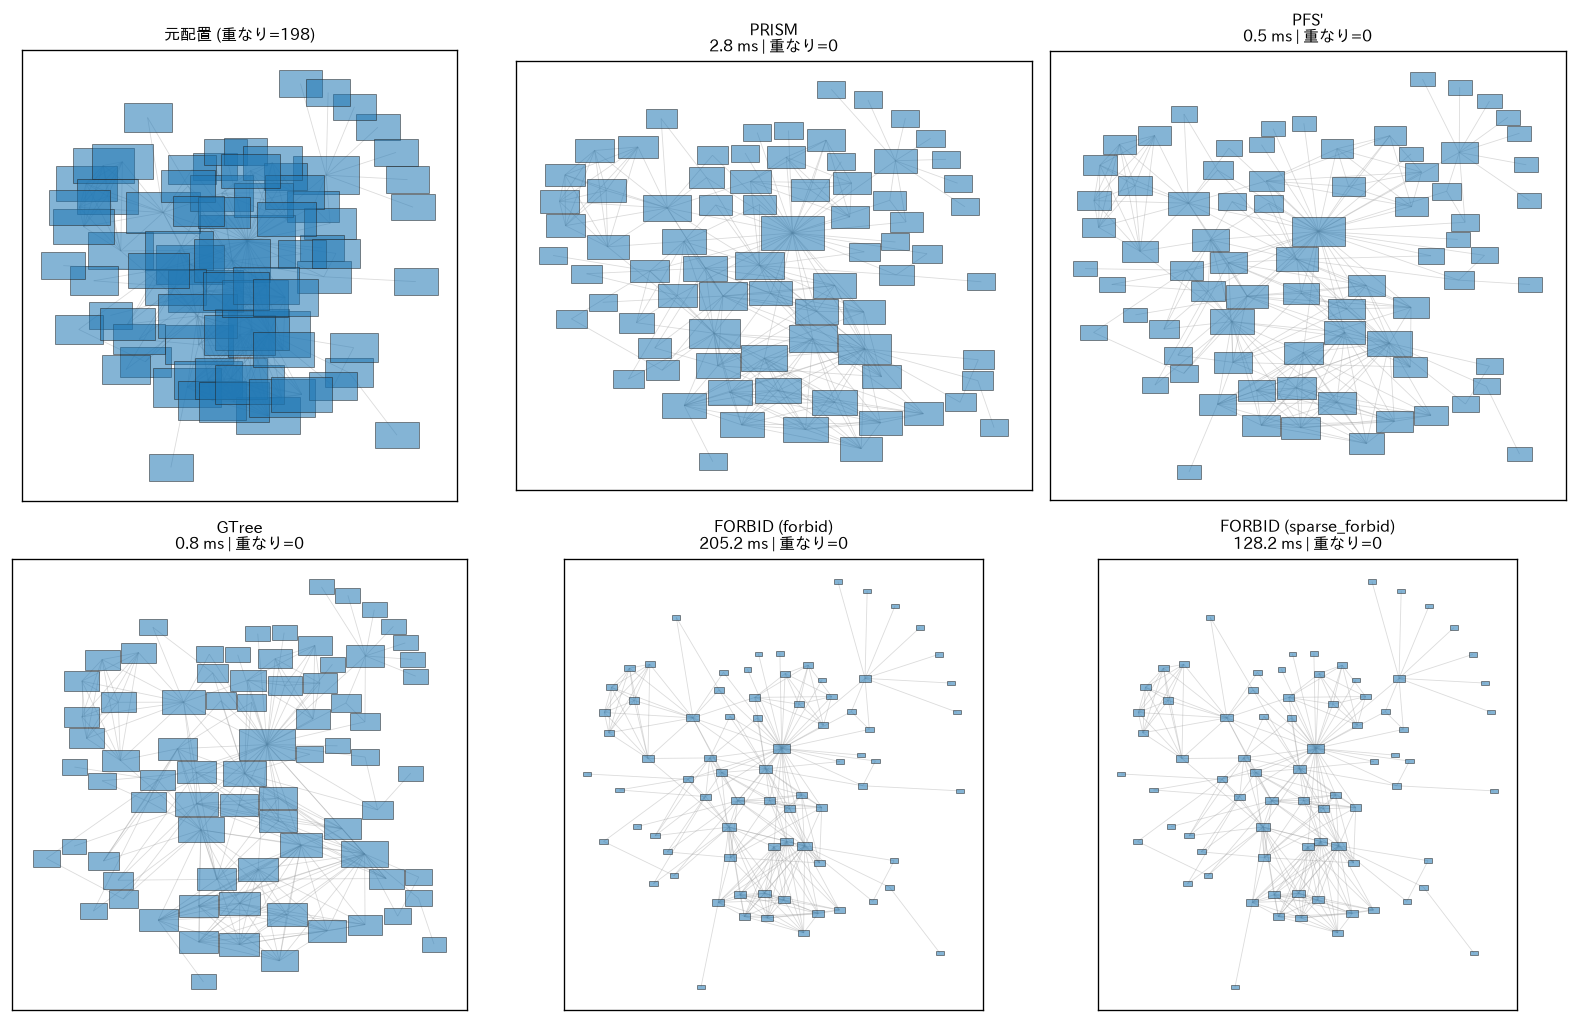

In [ ]:
# Prepare base Stress layout on lesmis with deliberate non-uniform node boxes
lay_lm0 = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
eg.StressMajorizationSolver.from_graph(g_lesmis).run(lay_lm0)
degs_lm = np.array([g_lesmis.degree(u) for u in range(g_lesmis.num_nodes)], dtype=np.float64)
hw_lm = 0.25 + 0.08 * np.sqrt(degs_lm)
hh_lm = 0.16 + 0.04 * np.sqrt(degs_lm)
radii_lm = hw_lm.copy()

ov_before_lm = len(eg.rectangle_overlaps(lay_lm0, hw_lm, hh_lm))
print(f"lesmis 初期重なり数: {ov_before_lm} ペア")

# Verify .from_radii matches (radii, radii)
lay_fr_a = eg.Layout2d.from_coords(lay_lm0.copy_coords())
lay_fr_b = eg.Layout2d.from_coords(lay_lm0.copy_coords())
eg.ForbidOverlapRemoval(radii_lm, radii_lm, variant="sparse_forbid", seed=42).run(lay_fr_a)
eg.ForbidOverlapRemoval.from_radii(radii_lm, variant="sparse_forbid", seed=42).run(lay_fr_b)
assert np.allclose(lay_fr_a.coords(copy=False), lay_fr_b.coords(copy=False))

# Compare all 4 solvers + all 3 FORBID variants on lesmis
solvers_lm = [
    ("PRISM", eg.PrismOverlapRemoval(hw_lm, hh_lm, padding=0.04, seed=42)),
    ("PFS'", eg.PfsPrimeOverlapRemoval(hw_lm, hh_lm, padding=0.04, seed=42)),
    ("GTree", eg.GTreeOverlapRemoval(hw_lm, hh_lm, padding=0.04, seed=42)),
    ("FORBID (forbid)", eg.ForbidOverlapRemoval(hw_lm, hh_lm, variant="forbid", padding=0.04, seed=42)),
    ("FORBID (forbid_prime)", eg.ForbidOverlapRemoval(hw_lm, hh_lm, variant="forbid_prime", padding=0.04, seed=42)),
    ("FORBID (sparse_forbid)", eg.ForbidOverlapRemoval(hw_lm, hh_lm, variant="sparse_forbid", padding=0.04, seed=42)),
]

print(f"{'ソルバ':<24} {'時間(ms)':>8} {'重なり(後)':>10} {'last_ov':>8} {'oo_nni':>8} {'sp_ch_a':>8} {'el_rsd':>8}")
print("-" * 80)
layouts_lm = {}
for name, solver in solvers_lm:
    lay = eg.Layout2d.from_coords(lay_lm0.copy_coords())
    t0 = time.perf_counter()
    solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    ov_after = len(eg.rectangle_overlaps(lay, hw_lm, hh_lm))
    ov_padded = len(eg.rectangle_overlaps(lay, hw_lm + 0.02, hh_lm + 0.02))
    nm = eg.nor_metrics(lay_lm0, lay, hw_lm, hh_lm)
    layouts_lm[name] = (lay, ms, ov_after)
    assert ov_padded == solver.last_overlap_count
    print(
        f"{name:<24} {ms:>8.2f} {ov_after:>10} {solver.last_overlap_count:>8} "
        f"{nm['oo_nni']:>8.4f} {nm['sp_ch_a']:>8.4f} {nm['el_rsd']:>8.4f}"
    )

# Also benchmark fast O(N log N) / sparse solvers on qh882 (N=882)
lay_qh0 = eg.pivot_mds_init(g_qh, seed=42)
hw_qh = np.full(g_qh.num_nodes, 0.35, dtype=np.float64)
hh_qh = np.full(g_qh.num_nodes, 0.25, dtype=np.float64)
print(f"\nqh882 初期重なり数: {len(eg.rectangle_overlaps(lay_qh0, hw_qh, hh_qh))} ペア")
for name, solver in [
    ("PRISM (qh882)", eg.PrismOverlapRemoval(hw_qh, hh_qh, seed=42)),
    ("PFS' (qh882)", eg.PfsPrimeOverlapRemoval(hw_qh, hh_qh, seed=42)),
    ("GTree (qh882)", eg.GTreeOverlapRemoval(hw_qh, hh_qh, seed=42)),
    ("sparse_forbid (qh882)", eg.ForbidOverlapRemoval(hw_qh, hh_qh, variant="sparse_forbid", seed=42)),
]:
    lay = eg.Layout2d.from_coords(lay_qh0.copy_coords())
    t0 = time.perf_counter()
    solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    print(f"  {name:<24} {ms:6.1f} ms | overlap_after={len(eg.rectangle_overlaps(lay, hw_qh, hh_qh))}")

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
plot_rect_nodes(g_lesmis, lay_lm0, hw_lm, hh_lm, axes[0, 0], title=f"元配置 (重なり={ov_before_lm})")
for ax, key in zip(
    [axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]],
    ["PRISM", "PFS'", "GTree", "FORBID (forbid)", "FORBID (sparse_forbid)"],
):
    lay_k, ms_k, ov_k = layouts_lm[key]
    plot_rect_nodes(g_lesmis, lay_k, hw_lm, hh_lm, ax, title=f"{key}\n{ms_k:.1f} ms | 重なり={ov_k}")

plt.tight_layout()
plt.show()

\
## 3. VPSC 分離制約射影とクラスタ単位重なり除去

- `project_rectangle_no_overlap_2d(layout, half_widths, half_heights)`: X/Y 交互の 1 次元 VPSC 射影により全矩形の重なりを 1 発で解消します。
- `project_clustered_rectangle_no_overlap_2d(layout, labels, half_widths, half_heights)`: 各クラスタの軸並行バウンディングボックス（AABB）同士が重ならないように VPSC 射影し、**各クラスタ内部の相対配置は剛体平行移動で完全に保持**します（クラスタ内部のノード重なり自体は変更しません）。

project_rectangle_no_overlap_2d: 0.96 ms, overlaps=0
project_clustered_rectangle_no_overlap_2d: 0.20 ms, max_intra_cluster_diff=4.44e-16


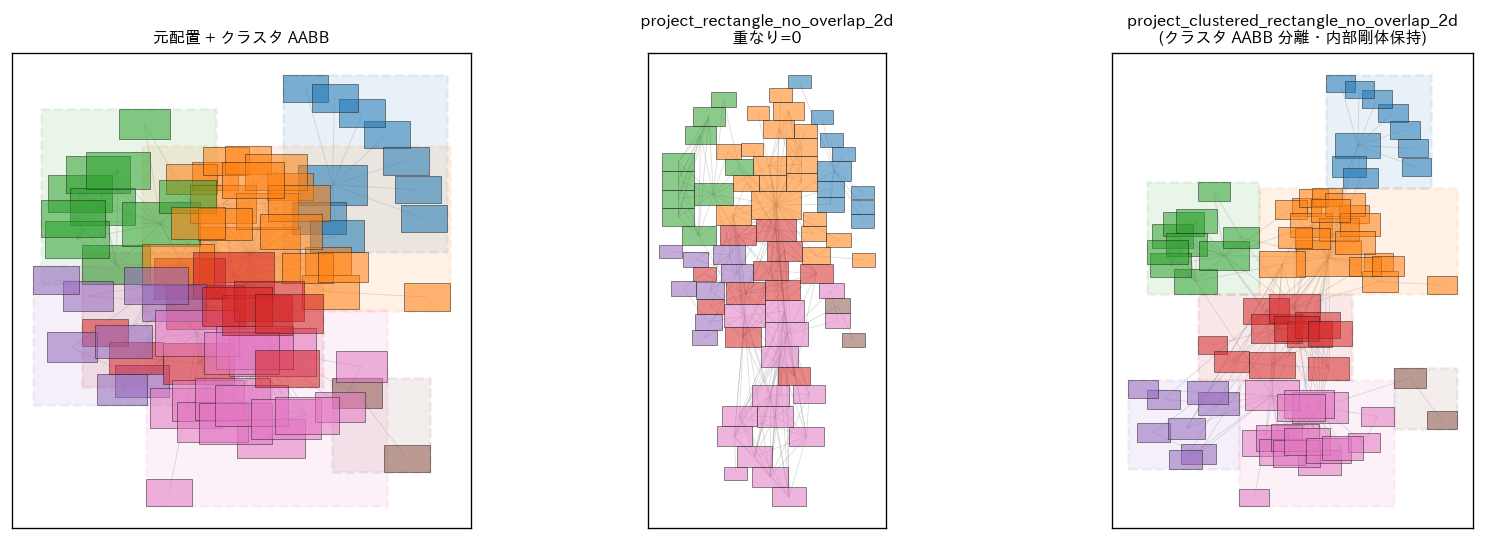

In [ ]:
\
lbl_lm = eg.louvain_communities(g_lesmis, seed=42).labels

# 1) Node-level VPSC projection
lay_vpsc = eg.Layout2d.from_coords(lay_lm0.copy_coords())
t0 = time.perf_counter()
eg.project_rectangle_no_overlap_2d(lay_vpsc, hw_lm, hh_lm)
ms_vpsc = (time.perf_counter() - t0) * 1000.0
ov_vpsc = len(eg.rectangle_overlaps(lay_vpsc, hw_lm, hh_lm))

# 2) Cluster-level VPSC projection (rigidly translates cluster AABBs)
lay_cvpsc = eg.Layout2d.from_coords(lay_lm0.copy_coords())
t0 = time.perf_counter()
eg.project_clustered_rectangle_no_overlap_2d(lay_cvpsc, lbl_lm, hw_lm, hh_lm)
ms_cvpsc = (time.perf_counter() - t0) * 1000.0

# Verify rigid intra-cluster offset preservation
c0 = lay_lm0.coords(copy=False)
c1 = lay_cvpsc.coords(copy=False)
max_intra_diff = 0.0
for cid in np.unique(lbl_lm):
    idx = np.where(lbl_lm == cid)[0]
    rel0 = c0[idx] - c0[idx[0]]
    rel1 = c1[idx] - c1[idx[0]]
    max_intra_diff = max(max_intra_diff, float(np.max(np.abs(rel0 - rel1))))

print(f"project_rectangle_no_overlap_2d: {ms_vpsc:.2f} ms, overlaps={ov_vpsc}")
print(f"project_clustered_rectangle_no_overlap_2d: {ms_cvpsc:.2f} ms, max_intra_cluster_diff={max_intra_diff:.2e}")


def draw_cluster_aabbs(coords: np.ndarray, labels: np.ndarray, hw: np.ndarray, hh: np.ndarray, ax):
    cmap = plt.get_cmap("tab10")
    for cid in np.unique(labels):
        idx = np.where(labels == cid)[0]
        xmin = float(np.min(coords[idx, 0] - hw[idx]))
        xmax = float(np.max(coords[idx, 0] + hw[idx]))
        ymin = float(np.min(coords[idx, 1] - hh[idx]))
        ymax = float(np.max(coords[idx, 1] + hh[idx]))
        ax.add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                facecolor=cmap(int(cid) % 10),
                alpha=0.10,
                edgecolor=cmap(int(cid) % 10),
                linewidth=1.5,
                linestyle="--",
                zorder=0,
            )
        )


fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
draw_cluster_aabbs(lay_lm0.coords(copy=False), lbl_lm, hw_lm, hh_lm, axes[0])
plot_rect_nodes(g_lesmis, lay_lm0, hw_lm, hh_lm, axes[0], title="元配置 + クラスタ AABB", cluster_labels=lbl_lm)

plot_rect_nodes(g_lesmis, lay_vpsc, hw_lm, hh_lm, axes[1], title=f"project_rectangle_no_overlap_2d\n重なり={ov_vpsc}", cluster_labels=lbl_lm)

draw_cluster_aabbs(lay_cvpsc.coords(copy=False), lbl_lm, hw_lm, hh_lm, axes[2])
plot_rect_nodes(g_lesmis, lay_cvpsc, hw_lm, hh_lm, axes[2], title="project_clustered_rectangle_no_overlap_2d\n(クラスタ AABB 分離・内部剛体保持)", cluster_labels=lbl_lm)
plt.tight_layout()
plt.show()

\
## 4. 空間侵入者リファイナ (`SpatialIntruderRefiner`) と双子頂点解消 (`TwinDeclutterer`)

- `SpatialIntruderRefiner`: 2-hop 近傍ではないのに空間的に近接している「空間侵入者（False Positives）」を検出し、局所ヒンジ反発で引き離すことで NP2 を改善します（`iterations=`）。`current_k_cap` と `set_k_cap()` で探索近傍上限も動的に調整できます。
- `TwinDeclutterer` / `declutter_twins_2d`: 同一位置へ縮退した双子頂点（構造同値頂点等）を近傍から微小半径で分離・整列し、`layout_degeneracy`（`excess_duplicate_ratio` / `near_collision_ratio`）の縮退を解消します。

Folded 4x6 grid: NP2 0.4395 -> 0.5338 | stats=173 FP detected
SpatialIntruderRefiner initial current_k_cap=24
After set_k_cap(40): current_k_cap=40
qh882 SpatialIntruderRefiner (39.3 ms): NP2 0.2862 -> 0.4454 | rounds=4, n_fp_total=10801, n_anchors=6132
TwinDeclutterer: clusters=6, moved=0 (fn=1) | excess_dup_ratio 0.333 -> 0.000, near_collision_ratio 0.667 -> 0.000


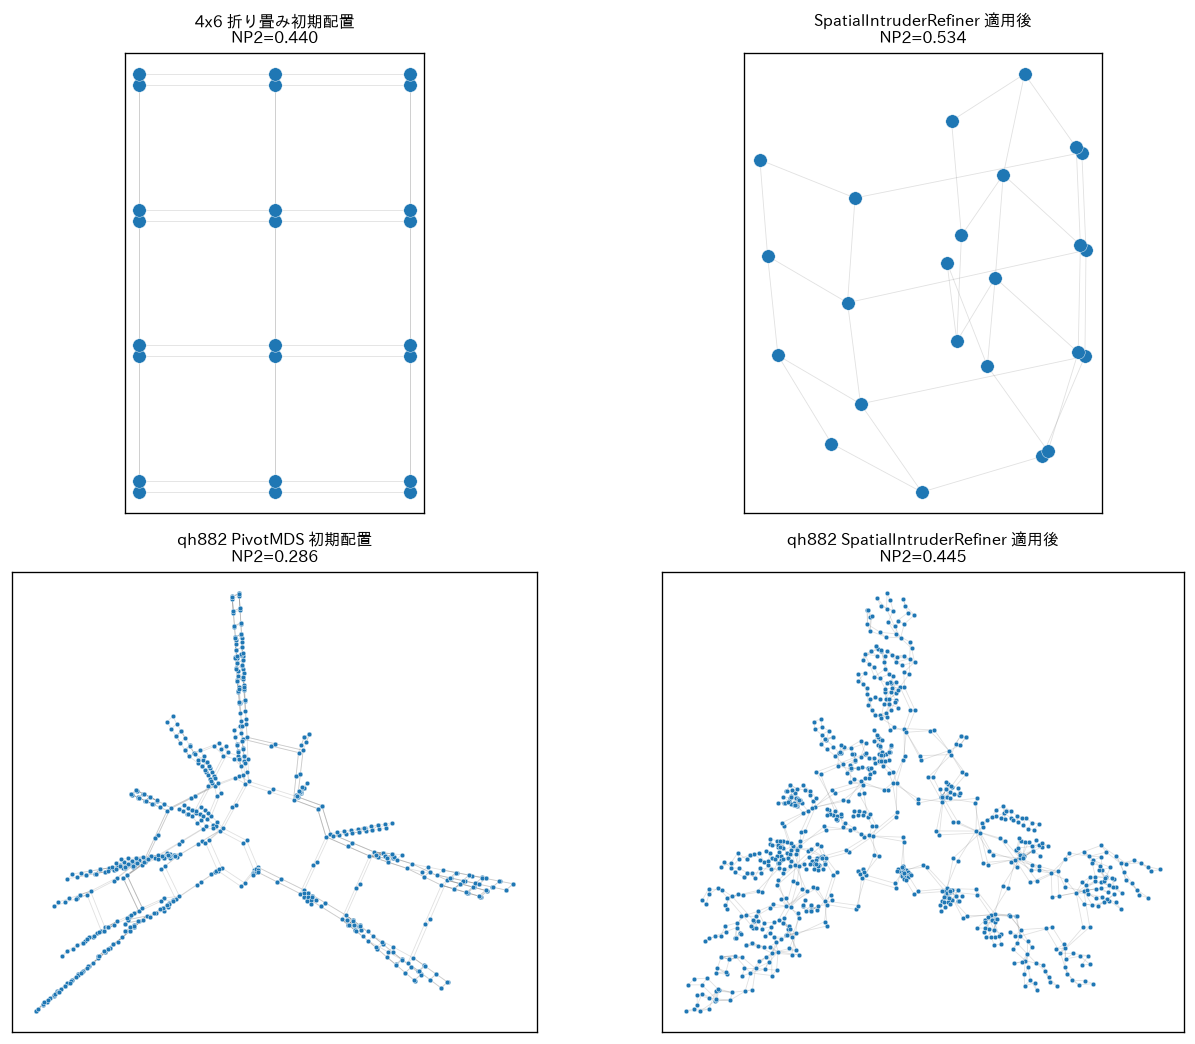

In [ ]:
\
# 1) Synthetic folded 4x6 grid graph to demonstrate spatial intruder unfolding clearly
rows, cols = 4, 6
grid_edges = []
for r in range(rows):
    for c in range(cols):
        u = r * cols + c
        if c + 1 < cols:
            grid_edges.append((u, u + 1))
        if r + 1 < rows:
            grid_edges.append((u, u + cols))
g_grid = eg.CsrGraph.from_edge_list(rows * cols, grid_edges, directed=False)

# Deliberately fold the right half back onto the left half
folded_coords = np.array(
    [[(c if c < 3 else 5 - c) * 1.0, r * 1.0 + (0.08 if c >= 3 else 0.0)] for r in range(rows) for c in range(cols)],
    dtype=np.float64,
)
lay_grid0 = eg.Layout2d.from_coords(folded_coords)
lay_grid1 = eg.Layout2d.from_coords(folded_coords.copy())

ref_grid = eg.SpatialIntruderRefiner(g_grid, iterations=4, k_cap=16, w_fp=0.4, w_anchor=1.0, seed=42)
ref_grid.run(lay_grid1)
np2_g0 = eg.evaluate_metrics(g_grid, lay_grid0, ["np2"]).neighborhood_preservation_2hop
np2_g1 = eg.evaluate_metrics(g_grid, lay_grid1, ["np2"]).neighborhood_preservation_2hop
print(f"Folded 4x6 grid: NP2 {np2_g0:.4f} -> {np2_g1:.4f} | stats={ref_grid.stats()['n_fp_total']} FP detected")

# 2) qh882 initialized by pivot_mds_init + dynamic set_k_cap
lay_qh_init = eg.pivot_mds_init(g_qh, seed=42)
lay_qh_ref = eg.Layout2d.from_coords(lay_qh_init.copy_coords())
ref_qh = eg.SpatialIntruderRefiner(g_qh, iterations=4, k_cap=24, w_fp=0.25, w_anchor=1.0, seed=42)
print(f"SpatialIntruderRefiner initial current_k_cap={ref_qh.current_k_cap}")
ref_qh.set_k_cap(40)
print(f"After set_k_cap(40): current_k_cap={ref_qh.current_k_cap}")

t0 = time.perf_counter()
ref_qh.run(lay_qh_ref)
ms_ref = (time.perf_counter() - t0) * 1000.0
st_qh = ref_qh.stats()
np2_q0 = eg.evaluate_metrics(g_qh, lay_qh_init, ["np2"]).neighborhood_preservation_2hop
np2_q1 = eg.evaluate_metrics(g_qh, lay_qh_ref, ["np2"]).neighborhood_preservation_2hop
print(
    f"qh882 SpatialIntruderRefiner ({ms_ref:.1f} ms): NP2 {np2_q0:.4f} -> {np2_q1:.4f} | "
    f"rounds={st_qh['rounds_executed']}, n_fp_total={st_qh['n_fp_total']}, n_anchors={st_qh['n_anchors_total']}"
)

# 3) TwinDeclutterer / declutter_twins_2d on collapsed duplicate vertices
g_twins = eg.CsrGraph.from_edge_list(6, [(0, 1), (0, 2), (0, 3), (1, 2), (3, 4), (3, 5)], directed=False)
twin_pts = np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 0.0], [2.0, 0.0], [3.0, 0.2], [3.0, 0.2]], dtype=np.float64)
lay_twin_a = eg.Layout2d.from_coords(twin_pts)
lay_twin_b = eg.Layout2d.from_coords(twin_pts.copy())
deg_before = eg.layout_degeneracy(g_twins, lay_twin_a)
decl = eg.TwinDeclutterer(iterations=4)
decl.run(lay_twin_a)
moved_fn = eg.declutter_twins_2d(lay_twin_b, iterations=4)
deg_after = eg.layout_degeneracy(g_twins, lay_twin_a)
print(
    f"TwinDeclutterer: clusters={decl.last_cluster_count}, moved={decl.last_moved_count} (fn={moved_fn}) | "
    f"excess_dup_ratio {deg_before['excess_duplicate_ratio']:.3f} -> {deg_after['excess_duplicate_ratio']:.3f}, "
    f"near_collision_ratio {deg_before['near_collision_ratio']:.3f} -> {deg_after['near_collision_ratio']:.3f}"
)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.8))
plot_graph_2d(g_grid, lay_grid0, axes[0, 0], title=f"4x6 折り畳み初期配置\nNP2={np2_g0:.3f}", node_size=65.0)
plot_graph_2d(g_grid, lay_grid1, axes[0, 1], title=f"SpatialIntruderRefiner 適用後\nNP2={np2_g1:.3f}", node_size=65.0)
plot_graph_2d(g_qh, lay_qh_init, axes[1, 0], title=f"qh882 PivotMDS 初期配置\nNP2={np2_q0:.3f}", node_size=8.0)
plot_graph_2d(g_qh, lay_qh_ref, axes[1, 1], title=f"qh882 SpatialIntruderRefiner 適用後\nNP2={np2_q1:.3f}", node_size=8.0)
plt.tight_layout()
plt.show()

\
## 5. スクリーン・ポアソン密度場 (`ScreenedPoissonField2d`) と密度場リファイン (`ScreenedPoissonRefiner`)

- `ScreenedPoissonField2d` は 2D FFT 上で密度場を畳み込み、超過密度エネルギーと反発力ベクトル `force_x`, `force_y`、さらに内部密度グリッド `density_grid()` (`(G, G)` 配列) を高速に計算します。既定の `grid_size=512`（`padding_factor=2`）は約 **4.14 MiB** の作業領域で動作し、軽量な探索には `grid_size=256`（約 1.04 MiB）も利用できます。
- `evaluate_in_bounds(layout, min_x, min_y, max_x, max_y)` は 4 つのスカラー境界引数を受け取ります。
- `ScreenedPoissonRefiner`（`__new__` / `.from_graph`）は `set_coarse_tether(coarse_layout, node_to_coarse)` により粗視化アンカーを保ちながら密度の過密を緩和します。`apply_epoch_step(layout)` で 1 エポックずつ統計（`last_stats()`, `last_energy`）を追跡できます。

ScreenedPoissonField2d(grid_size= 256): workspace_memory = 1.04 MiB
ScreenedPoissonField2d(grid_size= 512): workspace_memory = 4.14 MiB
ScreenedPoissonField2d(grid_size=2048): workspace_memory = 66.08 MiB
screened_poisson: energy=0.0023, max_dens=1.0945, excess_frac=0.0535, fft_calls=6, density_grid shape=(256, 256) (dim=256)
single_gaussian:  energy=0.0429, max_dens=1.0945, excess_frac=0.0535
evaluate_in_bounds keys (13): ['early_exit_no_excess', 'energy', 'excess_fraction', 'excess_mass', 'fft_2d_calls', 'force_x', 'force_y', 'grid_dim', 'kappa_used', 'max_density', 'pad_dim', 'rho_max_used', 'sigma_used']


ScreenedPoissonRefiner standalone final energy: 0.0000


apply_epoch_step energies: [0.0023, 0.0007, 0.0005, 0.0003, 0.0001, 0.0] | last_stats keys=11


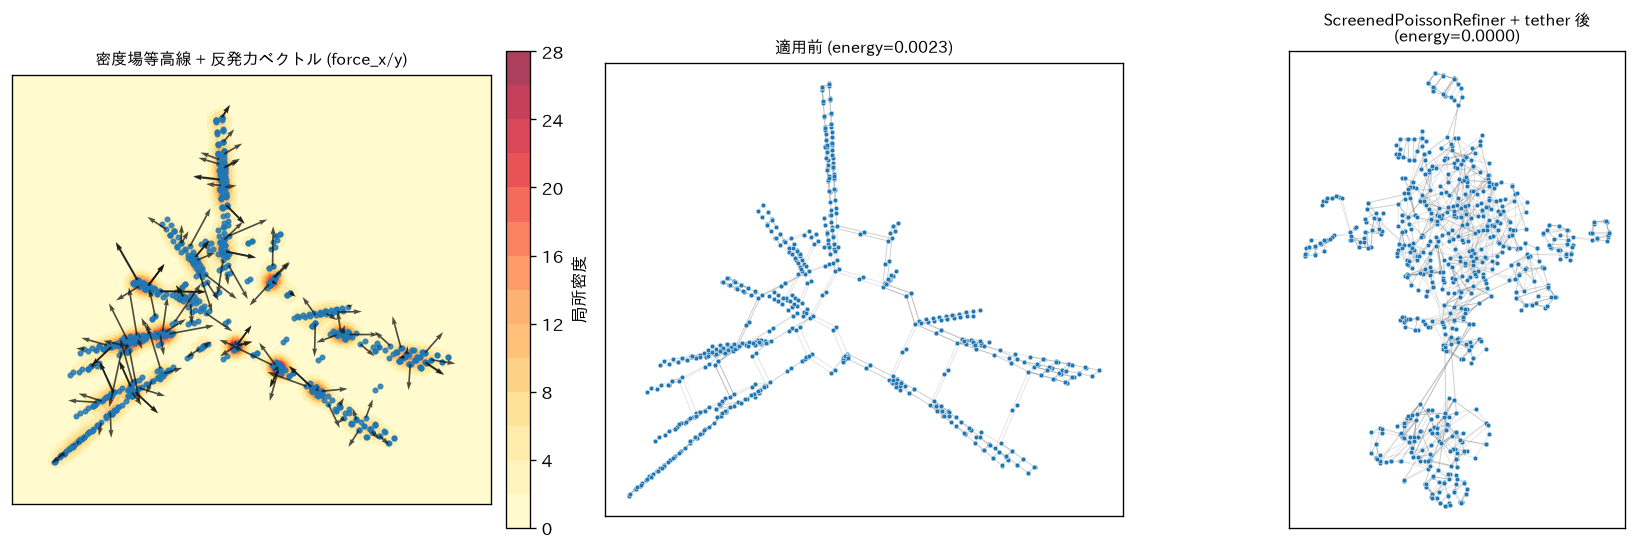

In [ ]:
\
# 1) Compare workspace_memory_bytes() across grid sizes 256 / 512 (default) / 2048
for gs in [256, 512, 2048]:
    mem_mib = eg.ScreenedPoissonField2d(grid_size=gs).workspace_memory_bytes() / (1024 * 1024)
    print(f"ScreenedPoissonField2d(grid_size={gs:>4}): workspace_memory = {mem_mib:.2f} MiB")

# 2) Evaluate "screened_poisson" vs "single_gaussian" on qh882 with grid_size=256 and density_grid()
field_sp = eg.ScreenedPoissonField2d(kernel="screened_poisson", grid_size=256)
field_sg = eg.ScreenedPoissonField2d(kernel="single_gaussian", grid_size=256)
res_sp = field_sp.evaluate(lay_qh_init)
res_sg = field_sg.evaluate(lay_qh_init)

c_qh = lay_qh_init.coords(copy=False)
min_x, max_x = float(c_qh[:, 0].min()), float(c_qh[:, 0].max())
min_y, max_y = float(c_qh[:, 1].min()), float(c_qh[:, 1].max())
res_bounds = field_sp.evaluate_in_bounds(lay_qh_init, min_x, min_y, max_x, max_y)
dg = field_sp.density_grid()
print(
    f"screened_poisson: energy={res_sp['energy']:.4f}, max_dens={res_sp['max_density']:.4f}, "
    f"excess_frac={res_sp['excess_fraction']:.4f}, fft_calls={res_sp['fft_2d_calls']}, "
    f"density_grid shape={dg.shape} (dim={field_sp.density_grid_dim})"
)
print(
    f"single_gaussian:  energy={res_sg['energy']:.4f}, max_dens={res_sg['max_density']:.4f}, "
    f"excess_frac={res_sg['excess_fraction']:.4f}"
)
print(f"evaluate_in_bounds keys ({len(res_bounds)}): {sorted(res_bounds.keys())}")

# 3) ScreenedPoissonRefiner standalone + from_graph with coarse tether
lc_qh = eg.louvain_coarsen(g_qh, max_coarse_nodes=40, seed=42)
coarse_qh = lc_qh["coarse_graph"]
coarse_lay_qh = eg.Layout2d.init(coarse_qh.num_nodes, seed=42)
eg.StressMajorizationSolver.from_graph(coarse_qh).run(coarse_lay_qh)

# Standalone ScreenedPoissonRefiner(num_nodes, ...)
lay_sp_plain = eg.Layout2d.from_coords(lay_qh_init.copy_coords())
ref_plain = eg.ScreenedPoissonRefiner(g_qh.num_nodes, grid_size=256, iterations=8, seed=42)
ref_plain.run(lay_sp_plain)
print(f"ScreenedPoissonRefiner standalone final energy: {ref_plain.last_energy:.4f}")

# Graph-anchored ScreenedPoissonRefiner.from_graph + set_coarse_tether + apply_epoch_step
lay_sp_tether = eg.Layout2d.from_coords(lay_qh_init.copy_coords())
ref_tether = eg.ScreenedPoissonRefiner.from_graph(
    g_qh,
    grid_size=256,
    iterations=12,
    anchor_weight=0.1,
    gamma_tether=0.15,
    seed=42,
)
ref_tether.set_coarse_tether(coarse_lay_qh, lc_qh["node_to_coarse"])
epoch_energies = []
for _ in range(6):
    st = ref_tether.apply_epoch_step(lay_sp_tether)
    epoch_energies.append(round(st["energy"], 4))
print(f"apply_epoch_step energies: {epoch_energies} | last_stats keys={len(ref_tether.last_stats())}")

# Compute smooth 2D Gaussian density contour on the initial layout for visualization
gx = np.linspace(min_x - 0.5, max_x + 0.5, 90)
gy = np.linspace(min_y - 0.5, max_y + 0.5, 90)
XX, YY = np.meshgrid(gx, gy)
sigma_vis = max(res_sp["sigma_used"], 0.15 * max(max_x - min_x, max_y - min_y) / 10.0)
diff2 = (XX[..., None] - c_qh[:, 0][None, None, :]) ** 2 + (YY[..., None] - c_qh[:, 1][None, None, :]) ** 2
density_vis = np.exp(-diff2 / (2.0 * sigma_vis ** 2)).sum(axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# Panel 1: Density contourf + force_x/force_y quiver vectors
ax0 = axes[0]
cf = ax0.contourf(XX, YY, density_vis, levels=16, cmap="YlOrRd", alpha=0.75, zorder=0)
plt.colorbar(cf, ax=ax0, fraction=0.046, pad=0.03, label="局所密度")
ax0.scatter(c_qh[:, 0], c_qh[:, 1], s=7, c="#1f77b4", alpha=0.8, zorder=2)
step_q = 6
ax0.quiver(
    c_qh[::step_q, 0],
    c_qh[::step_q, 1],
    res_sp["force_x"][::step_q],
    res_sp["force_y"][::step_q],
    color="#111111",
    alpha=0.75,
    scale_units="xy",
    width=0.0035,
    zorder=3,
)
ax0.set_aspect("equal")
ax0.set_xticks([])
ax0.set_yticks([])
ax0.set_title("密度場等高線 + 反発力ベクトル (force_x/y)", fontsize=9.5)

plot_graph_2d(g_qh, lay_qh_init, axes[1], title=f"適用前 (energy={res_sp['energy']:.4f})", node_size=8.0)
after_e = field_sp.evaluate(lay_sp_tether)["energy"]
plot_graph_2d(g_qh, lay_sp_tether, axes[2], title=f"ScreenedPoissonRefiner + tether 後\n(energy={after_e:.4f})", node_size=8.0)
plt.tight_layout()
plt.show()

\
## 6. Force-Directed Edge Bundling (`FdebSolver`)

`FdebSolver` は他のソルバと同じ統一 `IterativeSolver` インタフェースを採用しており、以下の仕様で動作します。

1. コンストラクタ `FdebSolver(graph, *, cycles=6, steps_per_cycle=90, dtype=..., ...)` はグラフのみを受け取り、`step(layout)` / `run_steps(layout, steps)` / `run(layout)` で `Layout2d` または `LayoutNd`（3D バンドリング対応）を渡します。
2. 入力 `layout` の座標は一切書き換えず、計算されたポリライン制御点は `edge_offsets()`・`points()`（および 3D 用の `points_z()` / `points_axis(d)`）で取得します。
3. Python 標準の `inspect.signature(eg.FdebSolver)` によるイントロスペクションも完全にサポートされています。

FdebSolver signature: (graph, *, cycles=6, s0=0.1, steps_per_cycle=90, s_step=0.5, i_step=0.6666666666666666, spring_k=0.1, minimum_edge_compatibility=0.6, dtype='float64')
FdebSolver [lesmis (float32)]: num_edges=254, dtype=float32, first_step=running, iters=161/161, status=completed, total_pts=16510, point_dims=2, time=17.5 ms


FdebSolver [qh882 (float64)]: num_edges=1533, dtype=float64, first_step=running, iters=101/101, status=completed, total_pts=50589, point_dims=2, time=196.9 ms


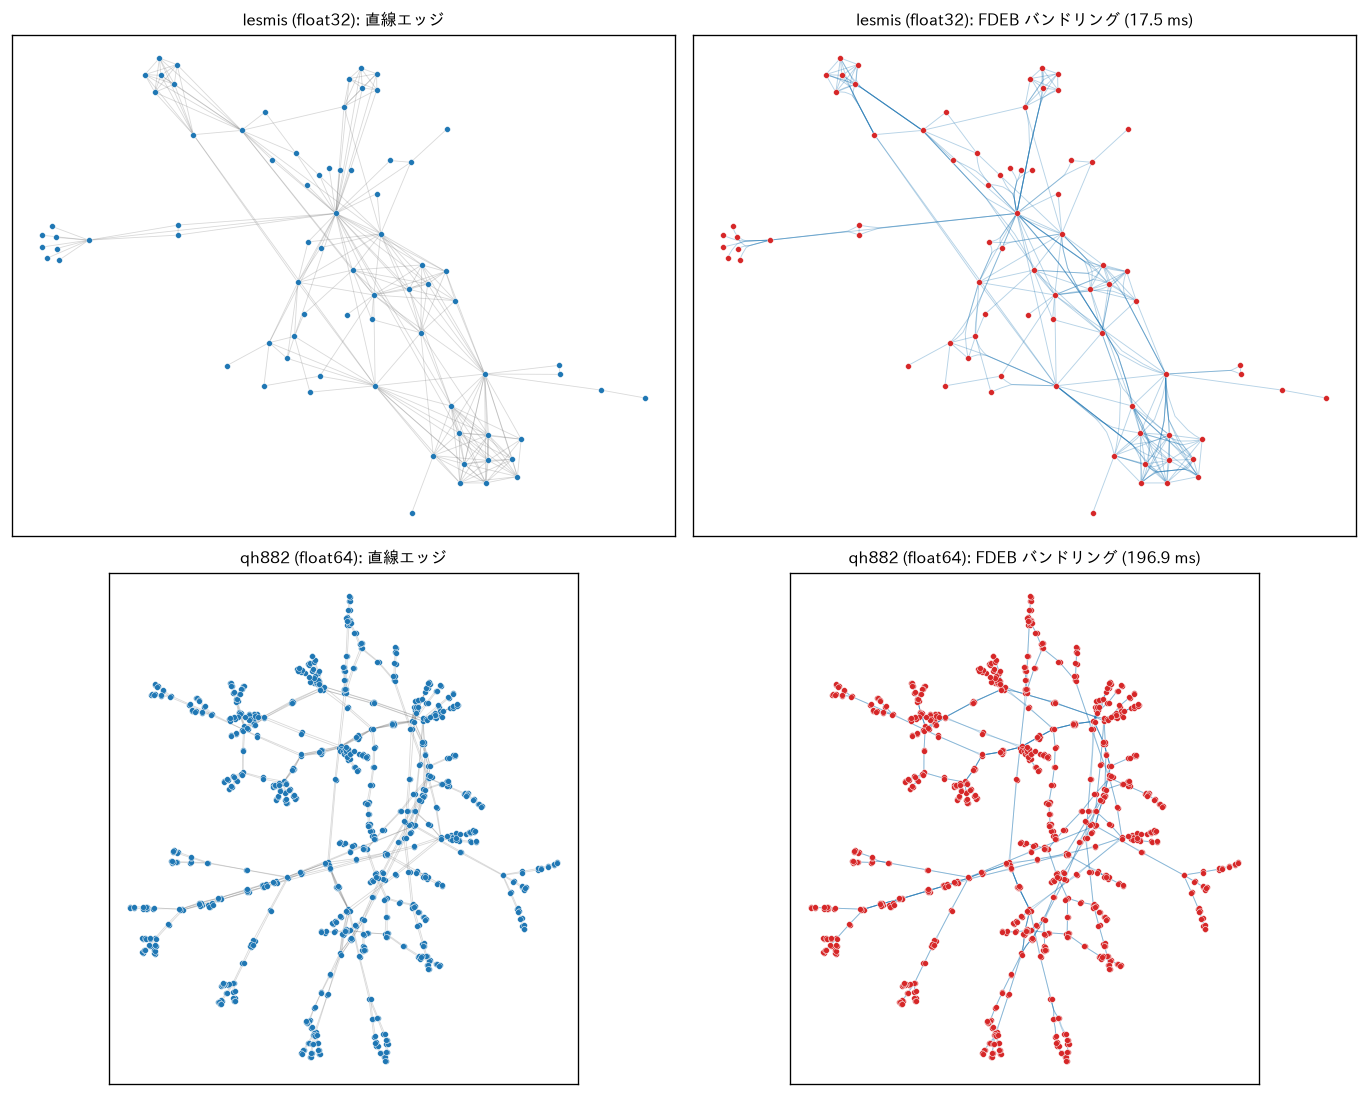

In [ ]:
\
print("FdebSolver signature:", inspect.signature(eg.FdebSolver))


def run_and_plot_fdeb(graph: eg.CsrGraph, lay_in: eg.Layout2d, cycles: int, steps_per_cycle: int, ax_raw, ax_bun, title_prefix: str):
    # Verify FdebSolver preserves input layout and supports both float32 and float64
    before = lay_in.copy_coords()
    t0 = time.perf_counter()
    fdeb = eg.FdebSolver(graph, cycles=cycles, steps_per_cycle=steps_per_cycle, dtype=lay_in.dtype)
    step_status = fdeb.step(lay_in)
    assert fdeb.iteration == 1
    fdeb.run_steps(lay_in, 20)
    fdeb.run(lay_in)
    ms = (time.perf_counter() - t0) * 1000.0
    assert np.array_equal(before, lay_in.coords(copy=False))

    offs = fdeb.edge_offsets()
    pts = fdeb.points()
    segments = [pts[int(offs[e]) : int(offs[e + 1])] for e in range(fdeb.num_edges)]

    print(
        f"FdebSolver [{title_prefix}]: num_edges={fdeb.num_edges}, dtype={fdeb.dtype}, "
        f"first_step={step_status}, iters={fdeb.iteration}/{fdeb.total_iterations}, status={fdeb.status}, "
        f"total_pts={len(pts)}, point_dims={fdeb.point_dims}, time={ms:.1f} ms"
    )

    plot_graph_2d(graph, lay_in, ax_raw, title=f"{title_prefix}: 直線エッジ", node_size=12.0, edge_alpha=0.28)
    coords = lay_in.coords(copy=False)
    ax_bun.add_collection(LineCollection(segments, colors="#1f77b4", linewidths=0.55, alpha=0.32, zorder=1))
    ax_bun.scatter(coords[:, 0], coords[:, 1], s=12.0, c="#d62728", edgecolors="white", linewidths=0.25, zorder=2)
    ax_bun.set_aspect("equal")
    ax_bun.autoscale_view()
    ax_bun.set_xticks([])
    ax_bun.set_yticks([])
    ax_bun.set_title(f"{title_prefix}: FDEB バンドリング ({ms:.1f} ms)", fontsize=9.5)


# Prepare layouts for lesmis (float32) and qh882 (float64)
lay_lm_f32 = eg.Layout2d.init(g_lesmis.num_nodes, seed=42, dtype="float32")
eg.ForceAtlas2Solver(g_lesmis, iterations=150, seed=42, dtype="float32").run(lay_lm_f32)

lay_qh_fa2 = eg.Layout2d.init(g_qh.num_nodes, seed=42)
eg.ForceAtlas2Solver(g_qh, iterations=150, seed=42).run(lay_qh_fa2)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 9.2))
run_and_plot_fdeb(g_lesmis, lay_lm_f32, cycles=6, steps_per_cycle=60, ax_raw=axes[0, 0], ax_bun=axes[0, 1], title_prefix="lesmis (float32)")
run_and_plot_fdeb(g_qh, lay_qh_fa2, cycles=5, steps_per_cycle=40, ax_raw=axes[1, 0], ax_bun=axes[1, 1], title_prefix="qh882 (float64)")
plt.tight_layout()
plt.show()